# Hypothesis 2 - Training Label Noise


### Importing libraries


In [1]:
import os
import json
from pathlib import Path
from importlib.metadata import version
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))


'12'

### Experiment settings


In [2]:
seed = 42
noise_level = [0.00, 0.10, 0.15, 0.25, 0.30, 0.40, 0.50]
noise_seed = [42]  # More seeds can be added later.
n_feature = 20
result_dir = Path("results/hypothesis_2")
result_dir.mkdir(parents=True, exist_ok=True)
metrics = [ "accuracy", "precision", "recall", "f1", "balanced_accuracy", "roc_auc", "pr_auc", "specificity" ]


In [ ]:
gb_param = { "n_estimators": 100, "learning_rate": 0.05, "max_depth": 3, "subsample": 1.0, "min_samples_split": 2, "random_state": seed }
assert noise_level[0] == 0
assert len(set(noise_level)) == len(noise_level)
assert all(0 <= noise <= 0.50 for noise in noise_level)
assert noise_seed and len(set(noise_seed)) == len(noise_seed)
print("Gradient Boosting settings:", gb_param)


Gradient Boosting settings: {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 1.0, 'min_samples_split': 2, 'random_state': 42}


### Data preparation


In [4]:
dt = joblib.load("starting_split.joblib")
x_train = dt["x_train"].copy()
y_train = dt["y_train"].copy()
print("Training rows:", len(x_train))
print("Test rows:", len(dt["x_test"]))
display(y_train.value_counts().rename_axis("Diabetes label").to_frame("Count"))


Training rows: 4507
Test rows: 1127


,Count
Diabetes label,
0.0,3685
1.0,822


In [ ]:
assert len(x_train) == 4507
assert len(dt["x_test"]) == 1127
assert x_train.index.is_unique
assert x_train.index.equals(y_train.index)
assert x_train.index.intersection(dt["x_test"].index).empty
assert not y_train.isna().any()
assert set(y_train.unique()) == {0, 1}


In [6]:
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
fold_index = list(cv.split(x_train, y_train))
val_row = np.concatenate([val_id for train_id, val_id in fold_index])
assert np.array_equal(np.sort(val_row), np.arange(len(x_train)))
print("Number of folds:", len(fold_index))


Number of folds: 5


In [7]:
def check_rows(data, path):
    saved_data = pd.read_csv(path, dtype=str).astype("string")
    current_data = data.reset_index(drop=True).astype("string")
    pd.testing.assert_frame_equal(saved_data, current_data, check_dtype=False)
    return saved_data


In [8]:
def read_mice(data, folder, raw_file, mice_file):
    raw_data = check_rows(data, folder / raw_file)
    mice_data = pd.read_csv(folder / mice_file)
    assert mice_data.shape == data.shape
    assert list(mice_data.columns) == list(data.columns)
    assert not mice_data.isna().any().any()
    # MICE should only replace missing values.
    same_value = mice_data.astype("string").eq(raw_data).fillna(False)
    assert not (raw_data.notna() & ~same_value).any().any()
    mice_data.index = data.index
    return mice_data


In [9]:
folds = []
for fold_no, (train_id, val_id) in enumerate(fold_index, start=1):
    folder = Path("mice_cache") / f"fold_{fold_no}"
    x_tr = read_mice(x_train.iloc[train_id], folder, "train.csv", "train_imputed.csv")
    x_val = read_mice(x_train.iloc[val_id], folder, "validation.csv", "validation_imputed.csv")
    folds.append({ "fold": fold_no, "train_id": train_id.copy(), "val_id": val_id.copy(), "x_tr_imputed": x_tr, "x_val_imputed": x_val,
        "y_tr": y_train.iloc[train_id].to_numpy(dtype=int, copy=True), "y_val": y_train.iloc[val_id].to_numpy(dtype=int, copy=True) })
    assert np.intersect1d(train_id, val_id).size == 0
    print("Loaded MICE data for fold", fold_no)


Loaded MICE data for fold 1
Loaded MICE data for fold 2
Loaded MICE data for fold 3
Loaded MICE data for fold 4
Loaded MICE data for fold 5


In [10]:
from sklearn.preprocessing import OneHotEncoder
for fold in folds:
    encoder = OneHotEncoder(handle_unknown="ignore", drop=None, sparse_output=False)
    x_tr = encoder.fit_transform(fold["x_tr_imputed"].astype(str))
    x_val = encoder.transform(fold["x_val_imputed"].astype(str))
    fold["x_tr"] = x_tr
    fold["x_val"] = x_val
    fold["feature_names"] = encoder.get_feature_names_out()
    print("Fold", fold["fold"], "- train:", x_tr.shape, "validation:", x_val.shape)


Fold 1 - train: (3605, 68) validation: (902, 68)
Fold 2 - train: (3605, 68) validation: (902, 68)
Fold 3 - train: (3606, 68) validation: (901, 68)
Fold 4 - train: (3606, 68) validation: (901, 68)
Fold 5 - train: (3606, 68) validation: (901, 68)


In [11]:
fold_rows = []
for fold in folds:
    for row in fold["val_id"]:
        fold_rows.append([int(row), x_train.index[row], fold["fold"]])
fold_table = pd.DataFrame( fold_rows, columns=["training_position", "original_index", "validation_fold"] )
fold_table.to_csv(result_dir / "fold_membership.csv", index=False)


### Add label noise


In [12]:
def change_labels(y_clean, noise, n_seed, fold_no):
    y_noise = y_clean.copy()
    n_change = int(np.floor(noise * len(y_clean)))
    random = np.random.default_rng(np.random.SeedSequence([n_seed, fold_no]))
    changed_idx = random.permutation(len(y_clean))[:n_change]
    y_noise[changed_idx] = 1 - y_clean[changed_idx]
    assert np.count_nonzero(y_noise != y_clean) == n_change
    return y_noise, changed_idx


In [13]:
runs = []
for n_seed in noise_seed:
    for noise in noise_level:
        for fold in folds:
            y_noise, changed_idx = change_labels( fold["y_tr"], noise, n_seed, fold["fold"] )
            run = fold.copy()
            run["noise_seed"] = n_seed
            run["noise_percent"] = int(round(noise * 100))
            run["y_changed"] = y_noise
            run["changed_rows"] = changed_idx
            runs.append(run)
print("Number of runs:", len(runs))


Number of runs: 35


### RFE20 and SMOTE


In [14]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
for run in runs:
    lr = LogisticRegression(solver="liblinear", max_iter=1000, random_state=seed)
    rfe = RFE(estimator=lr, n_features_to_select=n_feature, step=1)
    run["x_tr_selected"] = rfe.fit_transform(run["x_tr"], run["y_changed"])
    run["x_val_selected"] = rfe.transform(run["x_val"])
    run["selected_features"] = run["feature_names"][rfe.support_]
    assert run["x_tr_selected"].shape[1] == n_feature
    print("RFE done - noise:", run["noise_percent"], "fold:", run["fold"])


RFE done - noise: 0 fold: 1
RFE done - noise: 0 fold: 2
RFE done - noise: 0 fold: 3
RFE done - noise: 0 fold: 4
RFE done - noise: 0 fold: 5
RFE done - noise: 10 fold: 1
RFE done - noise: 10 fold: 2
RFE done - noise: 10 fold: 3
RFE done - noise: 10 fold: 4
RFE done - noise: 10 fold: 5
RFE done - noise: 15 fold: 1
RFE done - noise: 15 fold: 2
RFE done - noise: 15 fold: 3
RFE done - noise: 15 fold: 4
RFE done - noise: 15 fold: 5
RFE done - noise: 25 fold: 1
RFE done - noise: 25 fold: 2
RFE done - noise: 25 fold: 3
RFE done - noise: 25 fold: 4
RFE done - noise: 25 fold: 5
RFE done - noise: 30 fold: 1
RFE done - noise: 30 fold: 2
RFE done - noise: 30 fold: 3
RFE done - noise: 30 fold: 4
RFE done - noise: 30 fold: 5
RFE done - noise: 40 fold: 1
RFE done - noise: 40 fold: 2
RFE done - noise: 40 fold: 3
RFE done - noise: 40 fold: 4
RFE done - noise: 40 fold: 5
RFE done - noise: 50 fold: 1
RFE done - noise: 50 fold: 2
RFE done - noise: 50 fold: 3
RFE done - noise: 50 fold: 4
RFE done - noise: 5

In [ ]:
from imblearn.over_sampling import SMOTE
for run in runs:
    smote = SMOTE(random_state=seed)
    x_bal, y_bal = smote.fit_resample(run["x_tr_selected"], run["y_changed"])
    run["x_bal"] = x_bal
    run["y_bal"] = y_bal
print("SMOTE completed for all runs.")

c:\Users\chali\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\chali\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\chali\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 546, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\chali\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1022, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  

SMOTE completed for all runs.


### Gradient Boosting


In [16]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, balanced_accuracy_score, roc_auc_score
from sklearn.metrics import confusion_matrix, precision_recall_curve, auc
def get_scores(y_val, y_pred, y_prob):
    precision, recall, _ = precision_recall_curve(y_val, y_prob, pos_label=1)
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred, labels=[0, 1]).ravel()
    return [ accuracy_score(y_val, y_pred), precision_score(y_val, y_pred, pos_label=1, zero_division=0),
        recall_score(y_val, y_pred, pos_label=1, zero_division=0), f1_score(y_val, y_pred, pos_label=1, zero_division=0),
        balanced_accuracy_score(y_val, y_pred), roc_auc_score(y_val, y_prob), auc(recall, precision),
        recall_score(y_val, y_pred, pos_label=0, zero_division=0), int(tn), int(fp), int(fn), int(tp) ]


In [17]:
from sklearn.ensemble import GradientBoostingClassifier
for run in runs:
    gb = GradientBoostingClassifier(**gb_param)
    gb.fit(run["x_bal"], run["y_bal"])
    run["y_pred"] = gb.predict(run["x_val_selected"])
    run["y_prob"] = gb.predict_proba(run["x_val_selected"])[:, 1]
    run["scores"] = get_scores(run["y_val"], run["y_pred"], run["y_prob"])
    print( f"Seed {run['noise_seed']}, noise {run['noise_percent']}%, fold {run['fold']}: " f"recall = {run['scores'][2]:.4f}, F1 = {run['scores'][3]:.4f}" )


Seed 42, noise 0%, fold 1: recall = 0.6121, F1 = 0.4676
Seed 42, noise 0%, fold 2: recall = 0.6364, F1 = 0.4709
Seed 42, noise 0%, fold 3: recall = 0.6524, F1 = 0.4908
Seed 42, noise 0%, fold 4: recall = 0.6341, F1 = 0.4522
Seed 42, noise 0%, fold 5: recall = 0.6220, F1 = 0.4904
Seed 42, noise 10%, fold 1: recall = 0.6000, F1 = 0.4901
Seed 42, noise 10%, fold 2: recall = 0.6242, F1 = 0.4527
Seed 42, noise 10%, fold 3: recall = 0.6402, F1 = 0.4965
Seed 42, noise 10%, fold 4: recall = 0.5488, F1 = 0.4401
Seed 42, noise 10%, fold 5: recall = 0.6707, F1 = 0.4632
Seed 42, noise 15%, fold 1: recall = 0.5818, F1 = 0.4800
Seed 42, noise 15%, fold 2: recall = 0.5697, F1 = 0.4476
Seed 42, noise 15%, fold 3: recall = 0.6463, F1 = 0.4680
Seed 42, noise 15%, fold 4: recall = 0.6341, F1 = 0.4653
Seed 42, noise 15%, fold 5: recall = 0.6037, F1 = 0.4670
Seed 42, noise 25%, fold 1: recall = 0.5636, F1 = 0.4515
Seed 42, noise 25%, fold 2: recall = 0.6061, F1 = 0.4348
Seed 42, noise 25%, fold 3: recall =

### Results


In [18]:
score_rows = []
for run in runs:
    info = [run["noise_seed"], run["noise_percent"], run["fold"]]
    train_size = len(run["y_tr"])
    changed = len(run["changed_rows"])
    details = [ train_size, len(run["y_val"]), changed, 100 * changed / train_size, n_feature ]
    score_rows.append(info + details + run["scores"])


In [19]:
score_col = [ "noise_seed", "noise_percent", "fold", "n_train", "n_validation", "n_flipped", "actual_noise_percent", "features" ]
scores = pd.DataFrame(score_rows, columns=score_col + metrics + ["tn", "fp", "fn", "tp"])
scores.to_csv(result_dir / "fold_metrics.csv", index=False)
print("Total fold results:", len(scores))


Total fold results: 35


In [20]:
count_rows = []
for run in runs:
    y_clean = run["y_tr"]
    y_noise = run["y_changed"]
    changed = run["changed_rows"]
    count_rows.append([ run["noise_seed"], run["noise_percent"], run["fold"], int((y_clean == 0).sum()), int((y_clean == 1).sum()),
        int((y_clean[changed] == 0).sum()), int((y_clean[changed] == 1).sum()), int((y_noise == 0).sum()), int((y_noise == 1).sum()),
        int((run["y_bal"] == 0).sum()), int((run["y_bal"] == 1).sum()), int((run["y_val"] == 0).sum()), int((run["y_val"] == 1).sum()) ])


In [21]:
count_col = [ "noise_seed", "noise_percent", "fold", "clean_train_0", "clean_train_1", "flips_0_to_1", "flips_1_to_0", "noisy_train_0",
    "noisy_train_1", "smote_train_0", "smote_train_1", "validation_0", "validation_1" ]
counts = pd.DataFrame(count_rows, columns=count_col)
counts.to_csv(result_dir / "class_counts.csv", index=False)
display(counts)


,noise_seed,noise_percent,fold,clean_train_0,clean_train_1,flips_0_to_1,flips_1_to_0,noisy_train_0,noisy_train_1,smote_train_0,smote_train_1,validation_0,validation_1
0,42,0,1,2948,657,0,0,2948,657,2948,2948,737,165
1,42,0,2,2948,657,0,0,2948,657,2948,2948,737,165
2,42,0,3,2948,658,0,0,2948,658,2948,2948,737,164
3,42,0,4,2948,658,0,0,2948,658,2948,2948,737,164
4,42,0,5,2948,658,0,0,2948,658,2948,2948,737,164
5,42,10,1,2948,657,291,69,2726,879,2726,2726,737,165
6,42,10,2,2948,657,296,64,2716,889,2716,2716,737,165
7,42,10,3,2948,658,297,63,2714,892,2714,2714,737,164
8,42,10,4,2948,658,288,72,2732,874,2732,2732,737,164
9,42,10,5,2948,658,294,66,2720,886,2720,2720,737,164


In [22]:
feature_rows = []
for run in runs:
    for feature in run["selected_features"]:
        feature_rows.append([ run["noise_seed"], run["noise_percent"], run["fold"], feature ])
features = pd.DataFrame(feature_rows, columns=["noise_seed", "noise_percent", "fold", "feature"])
features.to_csv(result_dir / "rfe20_selected_features.csv", index=False)


In [23]:
changed_idx = []
for run in runs:
    for row in run["changed_rows"]:
        train_row = int(run["train_id"][row])
        changed_idx.append([ run["noise_seed"], run["noise_percent"], run["fold"], train_row, x_train.index[train_row], int(run["y_tr"][row]),
            int(run["y_changed"][row]) ])
change_col = [ "noise_seed", "noise_percent", "fold", "training_position", "original_index", "original_label", "changed_label" ]
changes = pd.DataFrame(changed_idx, columns=change_col)
changes.to_csv(result_dir / "flipped_training_rows.csv", index=False)


In [24]:
pred_rows = []
for run in runs:
    for row, actual, pred, prob in zip( run["val_id"], run["y_val"], run["y_pred"], run["y_prob"] ):
        pred_rows.append([ run["noise_seed"], run["noise_percent"], run["fold"], int(row), x_train.index[row], int(actual), int(pred), float(prob) ])
pred_col = [ "noise_seed", "noise_percent", "fold", "training_position", "original_index", "clean_label", "predicted_label", "diabetes_probability" ]
predictions = pd.DataFrame(pred_rows, columns=pred_col)
predictions.to_csv(result_dir / "validation_predictions.csv", index=False)


In [25]:
pd.testing.assert_frame_equal(x_train, dt["x_train"])
pd.testing.assert_series_equal(y_train, dt["y_train"])
for fold in folds:
    np.testing.assert_array_equal( fold["y_tr"], y_train.iloc[fold["train_id"]].to_numpy(dtype=int) )
    np.testing.assert_array_equal( fold["y_val"], y_train.iloc[fold["val_id"]].to_numpy(dtype=int) )
assert len(scores) == len(noise_seed) * len(noise_level) * 5
print("Original training and validation labels are unchanged.")


Original training and validation labels are unchanged.


In [26]:
seed_score = scores.groupby(["noise_seed", "noise_percent"])[metrics].mean().reset_index()
mean_score = seed_score.groupby("noise_percent")[metrics].mean()
std_score = scores.groupby(["noise_seed", "noise_percent"])[metrics].std()
score_diff = mean_score.subtract(mean_score.loc[0], axis="columns") * 100
seed_score.to_csv(result_dir / "seed_mean_scores.csv", index=False)
mean_score.to_csv(result_dir / "mean_scores.csv")
(mean_score * 100).to_csv(result_dir / "mean_scores_percent.csv")
std_score.to_csv(result_dir / "fold_standard_deviations.csv")
score_diff.to_csv(result_dir / "change_from_0_percent_pp.csv")


In [ ]:
metric_name = { "accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "F1 score", "balanced_accuracy": "Balanced accuracy",
    "roc_auc": "AUROC", "pr_auc": "PR-AUC", "specificity": "Specificity" }
print("Average scores (%)")
display((mean_score * 100).round(2).rename(columns=metric_name).rename_axis("Wrong labels (%)"))
print("Changes compared with 0% noise (percentage points)")
display(score_diff.round(2).rename(columns=metric_name).rename_axis("Wrong labels (%)"))

Average scores (%)


,Accuracy,Precision,Recall,F1 score,Balanced accuracy,AUROC,PR-AUC,Specificity
Wrong labels (%),,,,,,,,
0,74.44,38.03,63.14,47.44,70.05,77.42,44.84,76.96
10,74.44,37.92,61.68,46.85,69.48,75.58,43.01,77.29
15,74.57,37.84,60.71,46.56,69.19,75.76,44.12,77.67
25,73.73,36.82,59.74,45.34,68.29,73.51,39.01,76.85
30,71.67,33.44,55.47,41.62,65.38,69.55,35.01,75.28
40,60.75,25.21,57.29,34.91,59.41,62.76,28.27,61.52
50,50.67,18.70,49.02,26.93,50.03,49.03,18.61,51.04


Changes compared with 0% noise (percentage points)


,Accuracy,Precision,Recall,F1 score,Balanced accuracy,AUROC,PR-AUC,Specificity
Wrong labels (%),,,,,,,,
0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
10,-0.00,-0.11,-1.46,-0.59,-0.57,-1.85,-1.83,0.33
15,0.13,-0.19,-2.43,-0.88,-0.86,-1.66,-0.71,0.71
25,-0.71,-1.21,-3.41,-2.09,-1.76,-3.91,-5.83,-0.11
30,-2.77,-4.59,-7.67,-5.82,-4.68,-7.88,-9.83,-1.68
40,-13.69,-12.81,-5.85,-12.52,-10.64,-14.66,-16.57,-15.44
50,-23.77,-19.33,-14.12,-20.51,-20.02,-28.40,-26.22,-25.92


In [28]:
base_file = Path("results/baseline/gradient_boosting/cv_fold_metrics.csv")
zero_scores = scores[scores["noise_percent"] == 0].groupby("fold")[metrics].mean()
if base_file.exists():
    old_scores = pd.read_csv(base_file).rename(columns={ "Fold": "fold", "Accuracy": "accuracy", "Precision": "precision", "Recall": "recall",
        "F1-score": "f1", "AUROC": "roc_auc", "PR-AUC": "pr_auc" }).set_index("fold").sort_index()
    assert old_scores.index.tolist() == [1, 2, 3, 4, 5]
    compare_metric = [name for name in metrics if name in old_scores.columns]
    base_diff = (zero_scores[compare_metric] - old_scores[compare_metric]) * 100
    base_diff.to_csv(result_dir / "baseline_fold_differences_pp.csv")
    matches = np.allclose(zero_scores[compare_metric], old_scores[compare_metric], rtol=0, atol=1e-8)
    print("Baseline fold scores match:", bool(matches))
else:
    print("Saved baseline CSV missing. Compare with the rounded reported means.")


Baseline fold scores match: True


In [29]:
if base_file.exists():
    baseline_check = pd.DataFrame({ "original_baseline_percent": old_scores[compare_metric].mean() * 100,
        "rerun_0_percent": zero_scores[compare_metric].mean() * 100 })
    baseline_check["difference_pp"] = ( baseline_check["rerun_0_percent"] - baseline_check["original_baseline_percent"] )
else:
    reported = pd.Series({"accuracy": 74.44, "recall": 63.14, "f1": 47.44})
    baseline_check = pd.DataFrame({ "reported_baseline_percent": reported, "rerun_0_percent": mean_score.loc[0, reported.index] * 100 })
    baseline_check["difference_pp"] = ( baseline_check["rerun_0_percent"] - baseline_check["reported_baseline_percent"] )
baseline_check.to_csv(result_dir / "baseline_reproduction_check.csv")
display(baseline_check.round(4).rename(index=metric_name))


,original_baseline_percent,rerun_0_percent,difference_pp
Accuracy,74.4399,74.4399,0.0
Precision,38.0288,38.0288,0.0
Recall,63.1404,63.1404,0.0
F1 score,47.4366,47.4366,0.0
AUROC,77.4240,77.4240,0.0
PR-AUC,44.8372,44.8372,0.0


### Plots


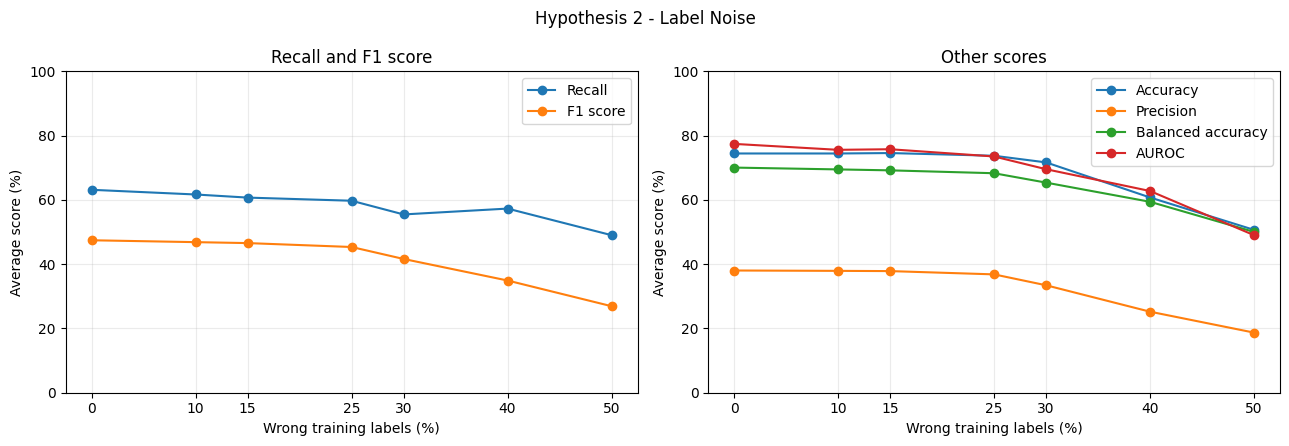

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for name in ["recall", "f1"]:
    axes[0].plot(mean_score.index, mean_score[name] * 100, marker="o", label=metric_name[name])
for name in ["accuracy", "precision", "balanced_accuracy", "roc_auc"]:
    axes[1].plot(mean_score.index, mean_score[name] * 100, marker="o", label=metric_name[name])
axes[0].set_title("Recall and F1 score")
axes[1].set_title("Other scores")
for axis in axes:
    axis.set_xlabel("Wrong training labels (%)")
    axis.set_ylabel("Average score (%)")
    axis.set_xticks(mean_score.index)
    axis.set_ylim(0, 100)
    axis.grid(alpha=0.25)
    axis.legend()
fig.suptitle("Hypothesis 2 - Label Noise")
fig.tight_layout()
fig.savefig(result_dir / "performance_by_label_noise.png", dpi=180, bbox_inches="tight")
plt.show()


In [31]:
baseline = mean_score.loc[0]
for noise, row in mean_score.drop(index=0).iterrows():
    recall_diff = (row["recall"] - baseline["recall"]) * 100
    f1_diff = (row["f1"] - baseline["f1"]) * 100
    print( f"{noise}% noise: recall {row['recall'] * 100:.2f}% ({recall_diff:+.2f} pp); " f"F1 {row['f1'] * 100:.2f}% ({f1_diff:+.2f} pp) compared with 0%." )
print("Recall falls at every step:", bool((mean_score["recall"].diff().dropna() < 0).all()))
print("Noise seeds:", noise_seed)
print("These results do not establish statistical significance.")


10% noise: recall 61.68% (-1.46 pp); F1 46.85% (-0.59 pp) compared with 0%.
15% noise: recall 60.71% (-2.43 pp); F1 46.56% (-0.88 pp) compared with 0%.
25% noise: recall 59.74% (-3.41 pp); F1 45.34% (-2.09 pp) compared with 0%.
30% noise: recall 55.47% (-7.67 pp); F1 41.62% (-5.82 pp) compared with 0%.
40% noise: recall 57.29% (-5.85 pp); F1 34.91% (-12.52 pp) compared with 0%.
50% noise: recall 49.02% (-14.12 pp); F1 26.93% (-20.51 pp) compared with 0%.
Recall falls at every step: False
Noise seeds: [42]
These results do not establish statistical significance.


### Save settings


In [32]:
settings = { "hypothesis": "Training label noise may reduce diabetes case detection.", "training_records": len(x_train),
    "held_out_test_records": len(dt["x_test"]), "noise_levels": noise_level, "noise_seeds": noise_seed,
    "noise_sampling": "uniform without replacement; nested subsets within seed/fold", "flip_count": "floor(noise_rate * fold_training_size)",
    "cv": {"n_splits": 5, "shuffle": True, "random_state": seed}, "gradient_boosting": gb_param, "validation_labels": "original clean labels",
    "test_set_used": False }


In [33]:
settings["rfe"] = { "estimator": "LogisticRegression", "solver": "liblinear", "max_iter": 1000, "n_features_to_select": n_feature, "step": 1,
    "random_state": seed }
settings["smote"] = {"random_state": seed, "k_neighbors": 5}
packages = ["numpy", "pandas", "scikit-learn", "imbalanced-learn", "joblib", "matplotlib"]
settings["package_versions"] = {name: version(name) for name in packages}
settings_file = result_dir / "experiment_config.json"
settings_file.write_text(json.dumps(settings, indent=2), encoding="utf-8")
print("Results saved in:", result_dir.resolve())


Results saved in: C:\NIBM\Coventry_CS_and_AI_Topup\Modules\Machine learning  and Related Applications\Analysis\results\hypothesis_2
